# Deeper - CNN
**Authors:** Kai Henrik Herbst & Bell Wassim
### Motivation
In our previous experiments, we observed that our baseline model suffered from severe memorization (overfitting). Because the architecture was relatively shallow, it lacked the capacity to learn complex, hierarchical features from the 96x96 pixel STL-10 images. 

In this notebook, we focus strictly on improving the **architectural capacity** of the network. We will implement a deeper architecture. By stacking two `Conv2D` layers before each `MaxPooling2D` operation, we can significantly increase the depth of the network without downsampling the spatial dimensions too quickly. Additionally, we introduce `BatchNormalization` after each convolutional layer to stabilize and accelerate the training process of this deeper network.

### 1. Data Loading and Preprocessing
Load the dataset and perform the necessary preprocessing.

In [1]:
# Import the data loading and preprocessing function from our utility script
# Note: Ensure the .py file is in the same directory
from data_prep import load_stl10_data

# Load the dataset. The function handles downloading, splitting (80/20), 
# resizing to 96x96, normalizing, and one-hot encoding the labels.
ds_train, ds_val, ds_test = load_stl10_data()

2026-03-22 10:22:56.154507: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-22 10:22:56.474241: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-03-22 10:22:58.819951: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


2026-03-22 10:23:06.148863: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:02:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-03-22 10:23:06.526788: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2251] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Dataset split: 4000 training, 1000 validation, 8000 testing.
Data preprocessing complete!


### 2. Network Creation (Deeper CNN)

To stop the model from simply memorizing the pixels, we need to give it a better chance to actually learn the underlying patterns. Therefore, we decided to make the network much deeper. However, we cannot simply add more alternating convolution and pooling layers, because our 96x96 images would shrink to 1x1 pixels too quickly. Here are the main changes we made to solve this problem:

* **Double Convolutions per Block:** Instead of just one convolution before pooling, we now stack two `Conv2D` layers. This makes the network deeper and increases its capacity to learn, without shrinking the spatial dimensions (pixels) too early.
* **More Filters (64 → 128 → 256 → 512):** We start with 64 filters and double them after every pooling step. This helps the network to pick up on a larger variety of complex features the deeper the image goes through the layers.
* **Padding="same":** We added this so the convolutions don't cut off the edges of our images.
* **Batch Normalization:** We added a Batch Normalization layer after every `Conv2D` and `Dense` layer. Because deeper networks can be a bit unstable during training, this helps to keep the numbers balanced and makes the learning process smoother and faster.
* **Bigger Dense Layer:** We added a Dense layer with 512 units at the end to better combine all the extracted features before the final classification.


In [2]:
import keras
from keras import layers

inputs = keras.Input(shape=(96, 96, 3))

# 1.Feature learning part
# Block 1
x = layers.Conv2D(64, kernel_size=3, padding="same", activation="relu")(inputs)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(64, kernel_size=3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D(pool_size=2)(x) # Downsamples to 48x48

# Block 2
x = layers.Conv2D(128, kernel_size=3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(128, kernel_size=3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D(pool_size=2)(x) # Downsamples to 24x24

# Block 3
x = layers.Conv2D(256, kernel_size=3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(256, kernel_size=3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D(pool_size=2)(x) # Downsamples to 12x12

# Block 4
x = layers.Conv2D(512, kernel_size=3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(512, kernel_size=3, padding="same", activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D(pool_size=2)(x) # Downsamples to 6x6

# 2.Classification Part
x = layers.Flatten()(x)

# A large dense layer to combine the extracted features
x = layers.Dense(512, activation="relu")(x)
x = layers.BatchNormalization()(x)

# Final output layer for 10 classes
outputs = layers.Dense(10, activation="softmax")(x)

model_deep = keras.Model(inputs=inputs, outputs=outputs, name="Deep_CNN_Style")

# Display architecture
model_deep.summary()

Model: "Deep_CNN_Style"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 96, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 96, 96, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 96, 96, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 48, 48, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 48, 48, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 48, 48, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 48, 48, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 24, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 24, 24, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 12, 12, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 12, 12, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 12, 12, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 12, 12, 512)    │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 512)      │             

 Total params: 14,137,930 (53.93 MB)

 Trainable params: 14,133,066 (53.91 MB)

 Non-trainable params: 4,864 (19.00 KB)

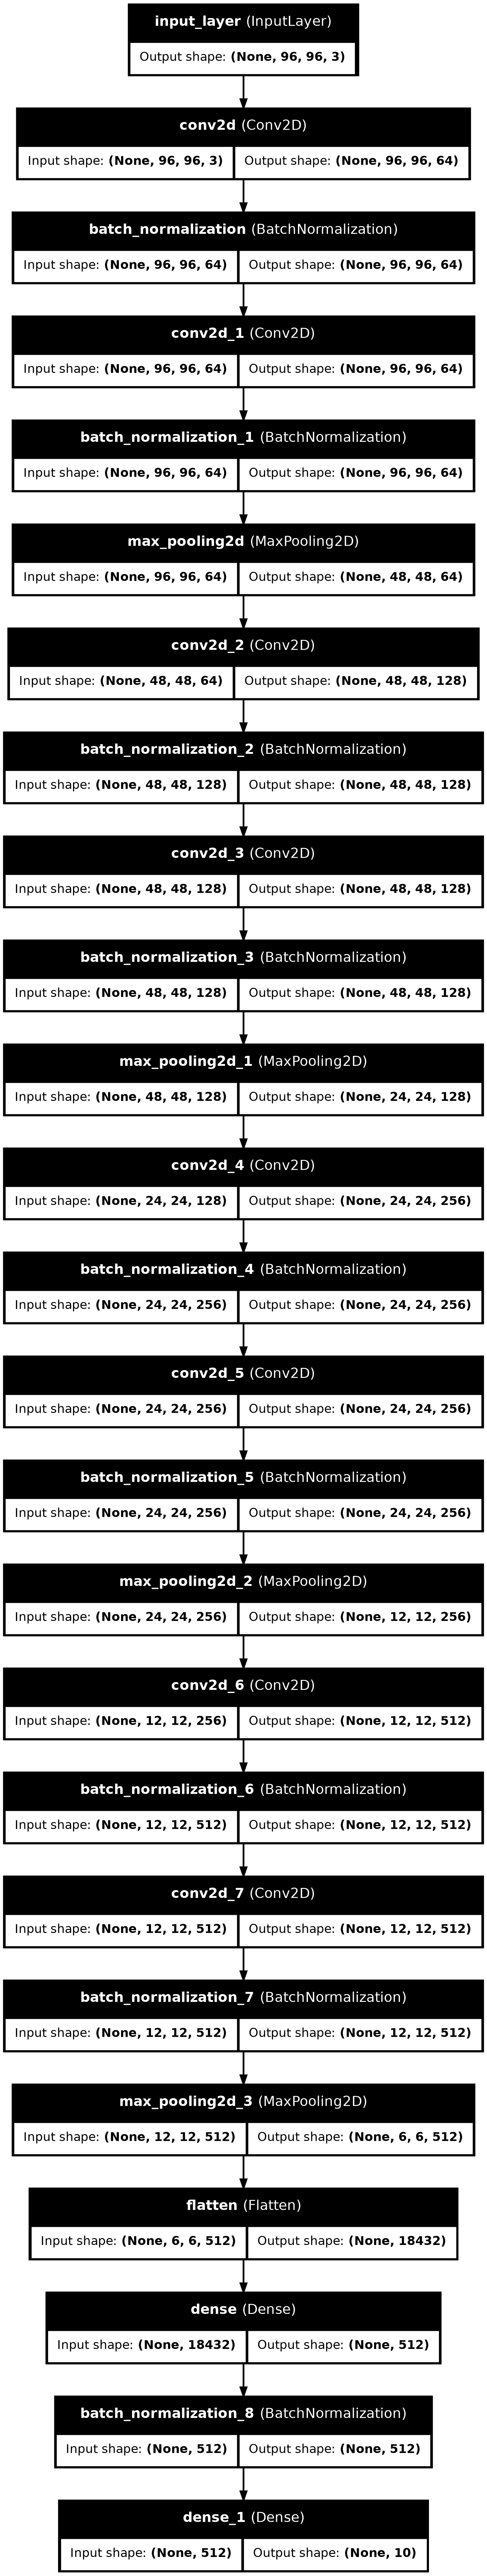

In [3]:
# Graphical visualization of the architecture (Academic Flowchart)
from tensorflow import keras

keras.utils.plot_model(model_deep, show_shapes=True, show_layer_names=True)

### 3. Model Training
First, we compile the model, specifying the optimiser and loss function. Then, we add the callbacks before training it on our preprocessed training data. We use the validation data to monitor the model's performance on unseen data and check for overfitting.

In [4]:
# Compile the model with the RMSprop optimizer, categorical crossentropy loss, and accuracy metric
model_deep.compile(
    optimizer='rmsprop',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
callbacks = [
    # We save the best model based on validation loss during training, under a new, appropriate name
    keras.callbacks.ModelCheckpoint(
        filepath="models/02_3_Deep_CNN.keras",
        save_best_only=True,
        monitor="val_loss"),
    
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True)
]

In [6]:
# Train the model for 30 epochs with the defined callbacks
print("Starting the training process for the deep architecture.")
history_deep = model_deep.fit(
    ds_train,
    epochs=30, 
    validation_data=ds_val,
    callbacks=callbacks
)

Starting the training process for the deep architecture.
Epoch 1/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 319s 5s/step - accuracy: 0.3137 - loss: 2.2395 - val_accuracy: 0.1130 - val_loss: 5.2212
Epoch 2/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 313s 5s/step - accuracy: 0.4355 - loss: 1.5619 - val_accuracy: 0.1100 - val_loss: 7.1203
Epoch 3/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 349s 6s/step - accuracy: 0.5325 - loss: 1.2806 - val_accuracy: 0.0970 - val_loss: 4.5393
Epoch 4/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 334s 5s/step - accuracy: 0.5955 - loss: 1.0928 - val_accuracy: 0.0860 - val_loss: 4.1469
Epoch 5/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 290s 5s/step - accuracy: 0.6522 - loss: 0.9641 - val_accuracy: 0.1350 - val_loss: 2.9421
Epoch 6/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 291s 5s/step - accuracy: 0.7128 - loss: 0.7996 - val_accuracy: 0.2390 - val_loss: 2.4565
Epoch 7/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 290s 5s/step - accuracy: 0.7717 - loss: 0.6352 - val_accuracy: 0.4860 - val_loss: 1.5187
Epoch 8/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 289s 5s/step - a

We visualize the training and validation progress to monitor the model's learning behavior.

In [7]:
import matplotlib.pyplot as plt

def plot(history):
    accuracy = history.history["accuracy"]
    val_accuracy = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]
    epochs = range(1, len(accuracy) + 1)

    plt.plot(epochs, accuracy, "b-o", label="Training accuracy")
    plt.plot(epochs, val_accuracy, "r--o", label="Validation accuracy")
    plt.title("Training and validation accuracy")
    plt.legend()
    plt.figure()

    plt.plot(epochs, loss, "b-o", label="Training loss")
    plt.plot(epochs, val_loss, "r-o", label="Validation loss")
    plt.title("Training and validation loss")
    plt.legend()
    plt.show()

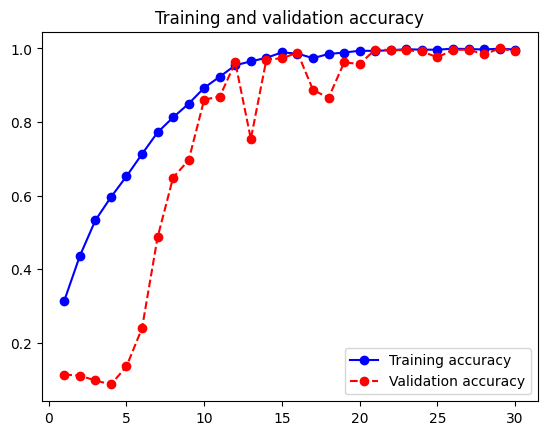

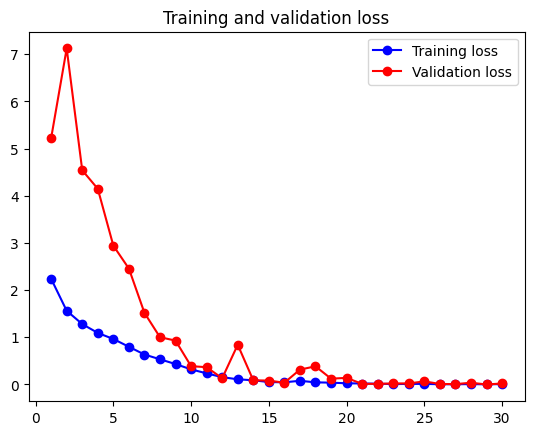

In [8]:
# After training, we can plot the training history to visualize the performance over epochs
plot(history_deep)

### 4. Evaluation
To determine the generalization capability of our deeper CNN model, we evaluate it using the test dataset (`ds_test`). Since these images were neither used for training nor for validation, the results provide an unbiased estimate of the model's performance in a real-world scenario.

In [9]:
# Evaluate the trained deep model on the unseen test dataset
print("Evaluating the deep model on the test dataset...")
test_loss, test_accuracy = model_deep.evaluate(ds_test)

print(f"\nFinal Test Loss: {test_loss:.3f}")
print(f"Final Test Accuracy: {test_accuracy * 100:.3f}%")

Evaluating the deep model on the test dataset...
125/125 ━━━━━━━━━━━━━━━━━━━━ 150s 1s/step - accuracy: 0.6850 - loss: 1.7183

Final Test Loss: 1.718
Final Test Accuracy: 68.500%


### 5. Result of Model 3
The transition to a deeper architecture with stacked convolutional layers and **Batch Normalization** yielded a significant performance boost, increasing the test accuracy from **52.7%** to **68.5%**. 

**Key Observations & Interpretation:**
* **Architectural Success:** The jump of nearly 16% in accuracy confirms our hypothesis: the baseline was too shallow. By increasing the **Architectural Capacity**, the network is now able to extract the hierarchical, complex features (edges, textures, and object parts) necessary for the STL-10 dataset.
* **Convergence with Batch Normalization:** The inclusion of Batch Normalization layers successfully stabilized the training of this deeper network, allowing it to reach nearly 100% training and validation accuracy within 30 epochs.
* **The Generalization Gap:** Despite the improved accuracy, we still observe a massive **Generalization Gap of ~31%** (100% Train/Val vs. 68.5% Test). This indicates that while the model *can* learn complex features, it is still choosing to **overfit** to the training distribution. The high Test Loss (1.718) further confirms that the model is struggling to maintain its confidence when faced with truly unseen data outside of the shuffled training/validation environment.

**Justification for Model 4:**
We have successfully solved the "capacity problem," but we now face a pure **Regularization Problem**. The model is powerful enough to understand the data, but it needs to be forced to learn **invariant features** that work on any image, not just our training samples. In the next step (Model 4), we will maintain this successful deep architecture but introduce **Data Augmentation** and **Dropout** to close the generalization gap and push for the 70%+ mark.